# What does the Pitwall Lab data tell us?
## From exploratory analysis to a first pace model

This notebook reads the **local race snapshots**, reuses `scripts/eda.py`, and takes us through:
1. Coverage and quality: which questions can these records answer?
2. Race results, pace, tyre age and weather: what do the patterns mean?
3. A conditional next-lap forecast: can a small ML model beat simple baselines?

**Prediction moment:** the end of a driver's current lap. **Target:** the next recorded lap, conditional on the same stint/compound and green-flag eligible timing. Pit transitions and interruptions are outside this first target.

Run all cells in order using the project `.venv` kernel. From the repository root install notebook dependencies with:
```sh
uv --cache-dir /tmp/pitwall-uv-cache pip install --python .venv/bin/python -r pyproject.toml --extra analysis
```
The delivered notebook includes executed tables and charts. It makes no network calls and does not change snapshots. The final cell writes a compact metrics summary to `analysis/ml/metrics.json`.

To execute and refresh saved outputs from the command line, run `.venv/bin/python scripts/run_notebook.py`. Select the repository `.venv/bin/python` interpreter when opening in a notebook editor.

In [1]:
from pathlib import Path
import os, sys, json, platform
os.environ.setdefault('MPLCONFIGDIR', '/tmp/pitwall-matplotlib')
os.environ.setdefault('OMP_NUM_THREADS', '2')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts' / 'eda.py').exists()), None)
assert ROOT is not None, 'Open this notebook inside the pitwall-lab repository.'
sys.path.insert(0, str(ROOT / 'scripts'))
import eda
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
eda.check()
print('Python:', platform.python_version(), '| pandas:', pd.__version__)
races, laps, results, weather = eda.load()
laps['compound'] = laps.compoundRaw.map(eda.compound)
clean = laps.loc[laps.eligible].copy()
display(pd.Series({'seasons': races.season.nunique(), 'calendar_entries': len(races),
                   'snapshots': races.coverage.ne('missing').sum(),
                   'timing_races': races.coverage.eq('timing').sum(),
                   'lap_records': len(laps), 'eligible_laps': len(clean),
                   'driver_result_entries': len(results), 'weather_rows': len(weather)}, name='count').to_frame())

EDA helper checks passed.
Python: 3.12.14 | pandas: 2.3.3


,count
seasons,77
calendar_entries,1172
snapshots,1164
timing_races,146
lap_records,160711
eligible_laps,131596
driver_result_entries,26203
weather_rows,21172


## 1. Coverage: many results, fewer detailed races
Historical classifications and modern timing are different datasets. An empty lap array in a results-only snapshot is intentional. Upcoming races have no outcomes yet.

**Question:** which seasons provide enough timing for pace modelling?

,laps,eligible,timing,results,missing
season,,,,,
2018,21410,16331,20,1,0
2019,23676,19737,21,0,0
2020,18350,14584,17,0,0
2021,23756,19956,22,0,0
2022,2990,2236,3,19,0
2023,0,0,0,22,0
2024,26604,22719,24,0,0
2025,26689,22242,24,0,0
2026,17236,13791,15,0,8


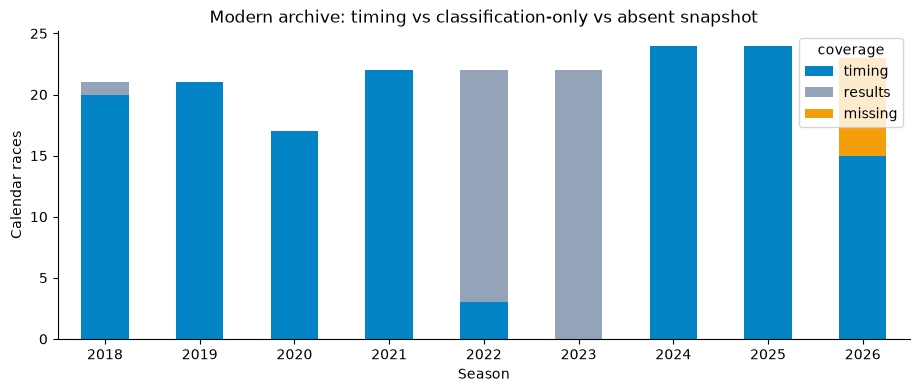

**Interpretation:** 2022 has partial timing and 2023 has none. The newest season is also incomplete. A random lap split would hide these gaps and share race-specific conditions between training and testing.

In [2]:
coverage = pd.crosstab(races.season, races.coverage).reindex(columns=['timing', 'results', 'missing'], fill_value=0)
yearly = races.groupby('season')[['laps', 'eligible']].sum().join(coverage)
display(yearly.loc[2018:])
coverage.loc[2018:].plot.bar(stacked=True, color=['#0284c7', '#94a3b8', '#f59e0b'])
plt.title('Modern archive: timing vs classification-only vs absent snapshot')
plt.ylabel('Calendar races'); plt.xlabel('Season'); plt.xticks(rotation=0); plt.show()
display(Markdown('**Interpretation:** 2022 has partial timing and 2023 has none. '
                 'The newest season is also incomplete. A random lap split would hide these gaps '
                 'and share race-specific conditions between training and testing.'))

## 2. Quality: missing values and eligibility
Eligible means positive, accurate, green-flag timing, excluding pit-in/out, deleted and generated laps. It does **not** mean dry conditions or traffic-free running.

Normalization happens in memory; it does not repair the original files.

,all_missing,eligible_missing,all_missing_pct
timeSeconds,2688,0,1.67
sector1,3449,0,2.15
sector2,328,0,0.20
sector3,432,0,0.27
position,239,0,0.15
tyreLife,852,485,0.53
sessionTimeSeconds,0,0,0.00
compound,821,409,0.51


,raw_compound_count
compoundRaw,
HARD,58274
MEDIUM,54002
SOFT,29337
INTERMEDIATE,7209
SUPERSOFT,5549
ULTRASOFT,4323
HYPERSOFT,887
nan,646
WET,309


,flagged_rows
duplicate_lap_keys,0
eligibility_mismatches,0
nonpositive_recorded_times,0
eligible_sector_sum_errors_over_20ms,0


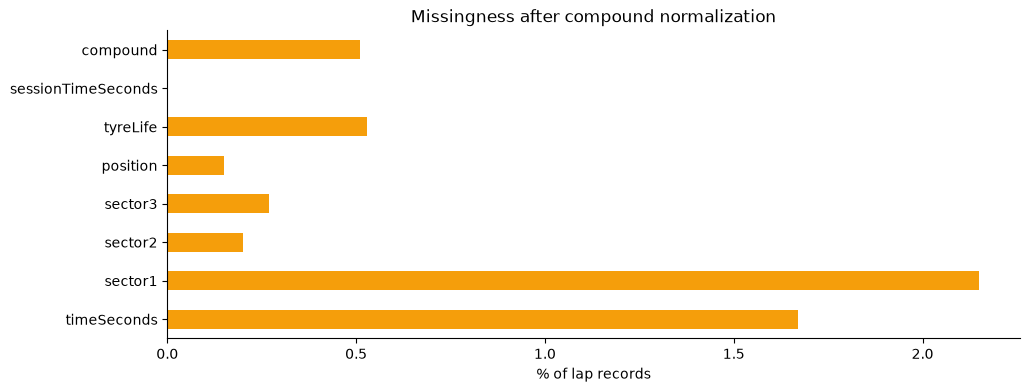

**Interpretation:** eligible laps still include 485 missing tyre ages and 409 unknown compounds. Missing values must not become zero. Clean timing flags do not prove every upstream measurement is correct.

In [3]:
fields = eda.FIELDS + ['compound']
quality = pd.DataFrame({'all_missing': laps[fields].isna().sum(),
                        'eligible_missing': clean[fields].isna().sum()})
quality['all_missing_pct'] = (100 * quality.all_missing / len(laps)).round(2)
display(quality)
display(laps.compoundRaw.fillna('<null>').value_counts().rename('raw_compound_count').to_frame())
checks = {'duplicate_lap_keys': int(laps.duplicated(['race', 'driver', 'number']).sum()),
          'eligibility_mismatches': int(laps.eligible.ne(laps.expectedEligible).sum()),
          'nonpositive_recorded_times': int((laps.timeSeconds.notna() & laps.timeSeconds.le(0)).sum())}
sectors = clean.dropna(subset=['sector1', 'sector2', 'sector3'])
checks['eligible_sector_sum_errors_over_20ms'] = int((sectors[['sector1', 'sector2', 'sector3']].sum(axis=1) - sectors.timeSeconds).abs().gt(.02).sum())
display(pd.Series(checks, name='flagged_rows').to_frame())
quality[['all_missing_pct']].plot.barh(color='#f59e0b', legend=False)
plt.xlabel('% of lap records'); plt.title('Missingness after compound normalization'); plt.show()
assert checks['duplicate_lap_keys'] == 0, 'Resolve duplicate identities before constructing targets.'
assert checks['eligibility_mismatches'] == 0, 'Investigate eligibility changes before continuing.'
display(Markdown(f'**Interpretation:** eligible laps still include {clean.tyreLife.isna().sum():,} '
                 f'missing tyre ages and {clean.compound.isna().sum():,} unknown compounds. '
                 'Missing values must not become zero. Clean timing flags do not prove every upstream measurement is correct.'))

## 3. Historical results: does starting position matter?
Use race-entry records from 2000 onward with valid positive grid/finish positions. Exclude DNS, nonqualification, withdrawal and disqualification; classified retirements remain. Shared-drive and historical provider conventions limit cross-era comparisons.

This is an association study, not a pre-race model: **finishing position is an outcome**, never a forecast input. Race points also exclude sprint points.

,entries,races,median_grid,median_finish,grid_finish_spearman
era,,,,,
2000s,3635,174,11.0,11.0,0.507
2010s,4249,197,11.0,11.0,0.627
2020s,2915,146,11.0,11.0,0.631


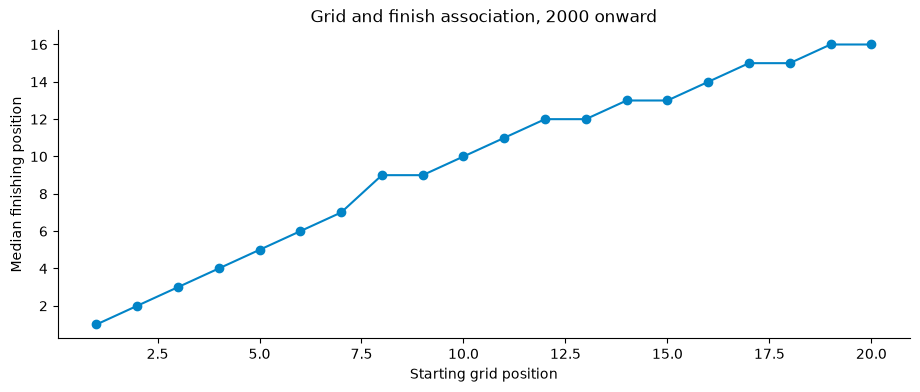

**Interpretation:** starting position is a useful candidate predictor, but this pattern also reflects car and driver strength, reliability and race context. It does not measure the causal benefit of moving a car one grid place forward. Era differences matter.

In [4]:
bad_status = results.status.str.contains('disqualified|did not start|did not qualify|did not prequalify|withdrawn|excluded', case=False, na=False)
classified = results.loc[(results.season >= 2000) & results.grid.gt(0) & results.position.gt(0) & ~bad_status].copy()
classified['era'] = (classified.season // 10 * 10).astype(str) + 's'
result_summary = classified.groupby('era').agg(entries=('code', 'size'), races=('race', 'nunique'),
                                              median_grid=('grid', 'median'), median_finish=('position', 'median'))
result_summary['grid_finish_spearman'] = classified.groupby('era')[['grid', 'position']].apply(lambda g: g.grid.corr(g.position, method='spearman'))
display(result_summary.round(3))
grid_summary = classified.loc[classified.grid.le(20)].groupby('grid').agg(entries=('code', 'size'), median_finish=('position', 'median'))
grid_summary.median_finish.plot(marker='o', color='#0284c7')
plt.xlabel('Starting grid position'); plt.ylabel('Median finishing position')
plt.title('Grid and finish association, 2000 onward'); plt.show()
display(Markdown('**Interpretation:** starting position is a useful candidate predictor, but this pattern '
                 'also reflects car and driver strength, reliability and race context. It does not measure '
                 'the causal benefit of moving a car one grid place forward. Era differences matter.'))

## 4. Pace: circuit context comes first
A lap at Spa and a lap at the Red Bull Ring are different tasks. Even circuit names can have aliases or changed layouts.

For EDA only, subtract each driver's **full-race median** to examine relative pace. That median sees future laps, so it must never enter a predictive feature table.

,count,median
circuit,,
Red Bull Ring,9814,70.384
Autódromo José Carlos Pace,5154,74.938
Circuit Park Zandvoort,1261,76.390
Circuit Zandvoort,3430,76.532
Circuit Gilles Villeneuve,5176,77.158
Circuit de Monaco,7357,78.351
Hockenheimring,1069,80.346
Autodromo Enzo e Dino Ferrari,3747,81.263
Autódromo Hermanos Rodríguez,5558,82.345


,seconds_from_driver_race_median
0.01,-2.55107
0.10,-1.32100
0.50,0.00000
0.90,1.44370
0.99,3.45657


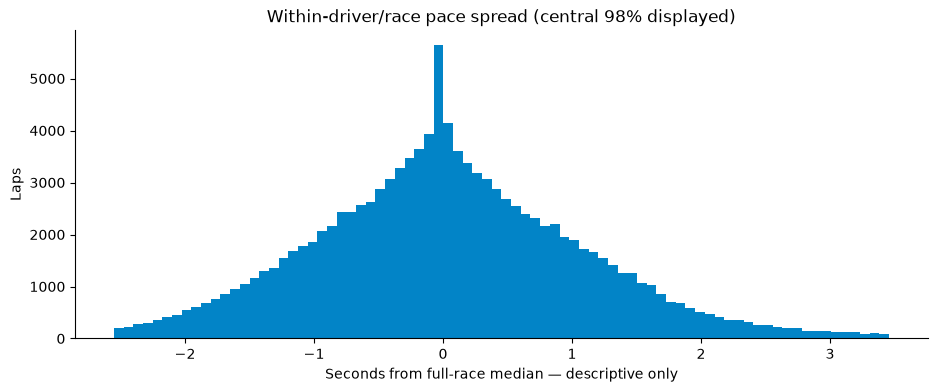

**Interpretation:** race/circuit context is essential. The sharp spike around zero partly comes from centering on each group median. Raw compound averages would also mix circuits, drivers, eras and race phases.

In [5]:
circuit_pace = clean.groupby('circuit').timeSeconds.agg(['count', 'median'])
display(circuit_pace.query('count >= 500').sort_values('median').round(3))
dry_compounds = clean.loc[clean.compound.isin(['SOFT', 'MEDIUM', 'HARD'])].copy()
dry_compounds['descriptive_delta'] = dry_compounds.timeSeconds - dry_compounds.groupby(['race', 'driver']).timeSeconds.transform('median')
display(dry_compounds.descriptive_delta.quantile([.01, .1, .5, .9, .99]).rename('seconds_from_driver_race_median').to_frame())
lo, hi = dry_compounds.descriptive_delta.quantile([.01, .99])
plt.hist(dry_compounds.descriptive_delta, bins=80, range=(lo, hi), color='#0284c7')
plt.title('Within-driver/race pace spread (central 98% displayed)')
plt.xlabel('Seconds from full-race median — descriptive only'); plt.ylabel('Laps'); plt.show()
display(Markdown('**Interpretation:** race/circuit context is essential. The sharp spike around zero '
                 'partly comes from centering on each group median. Raw compound averages would also '
                 'mix circuits, drivers, eras and race phases.'))

## 5. Tyre age: why a simple degradation slope misleads
Tyres usually age as the race progresses, while fuel burns off. Drivers select compounds and stint lengths in response to conditions. SOFT/MEDIUM/HARD are weekend-relative labels, not physical compound IDs.

Plot within-stint deviations and the sample counts together. These are **observed pace patterns**, not isolated tyre wear effects.

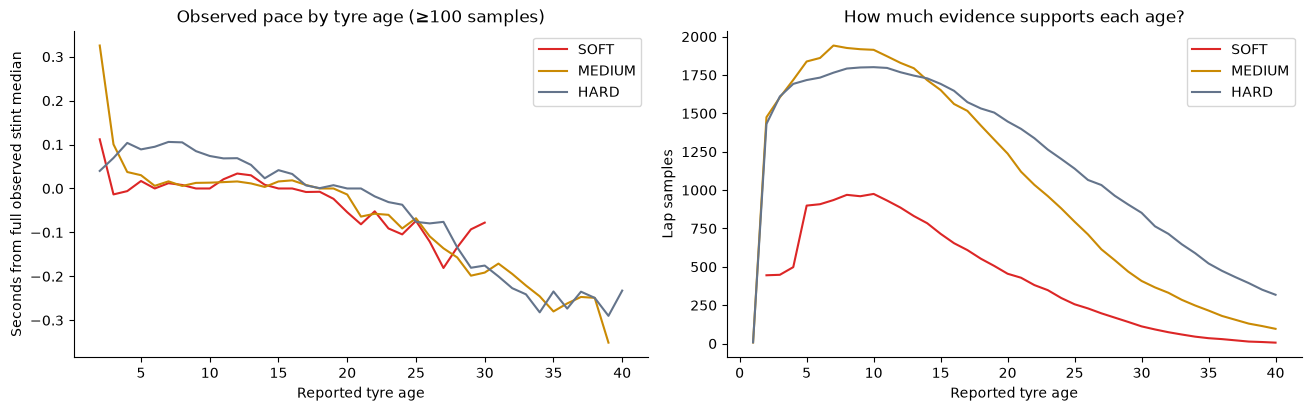

,number,tyreLife,timeSeconds,stint_delta
number,1.000,0.513,-0.270,-0.061
tyreLife,0.513,1.000,-0.140,-0.115
timeSeconds,-0.270,-0.140,1.000,0.106
stint_delta,-0.061,-0.115,0.106,1.000


**Interpretation:** pooled laps can get faster as tyres age. This does not mean tyres improve indefinitely; fuel, track evolution and selection can outweigh wear. Long-age observations come from the stints that survived that long. A predictive tyre-age effect should not be presented as causal degradation.

In [6]:
tyres = dry_compounds.loc[(dry_compounds.season >= 2019) & dry_compounds.tyreLife.notna()].copy()
tyres['stint_delta'] = tyres.timeSeconds - tyres.groupby(['race', 'driver', 'stint', 'compound']).timeSeconds.transform('median')
profile = tyres.loc[tyres.tyreLife.between(1, 40)].groupby(['compound', 'tyreLife']).stint_delta.agg(['median', 'count'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for name, color in [('SOFT', '#dc2626'), ('MEDIUM', '#ca8a04'), ('HARD', '#64748b')]:
    frame = profile.loc[name]
    enough = frame.loc[frame['count'] >= 100]
    axes[0].plot(enough.index, enough['median'], label=name, color=color)
    axes[1].plot(frame.index, frame['count'], label=name, color=color)
axes[0].set(title='Observed pace by tyre age (≥100 samples)', xlabel='Reported tyre age', ylabel='Seconds from full observed stint median')
axes[1].set(title='How much evidence supports each age?', xlabel='Reported tyre age', ylabel='Lap samples')
for ax in axes: ax.legend()
plt.show()
display(tyres[['number', 'tyreLife', 'timeSeconds', 'stint_delta']].corr().round(3))
display(Markdown('**Interpretation:** pooled laps can get faster as tyres age. This does not mean '
                 'tyres improve indefinitely; fuel, track evolution and selection can outweigh wear. '
                 'Long-age observations come from the stints that survived that long. A predictive '
                 'tyre-age effect should not be presented as causal degradation.'))

## 6. Weather: what was known at the prediction moment?
Our first prediction happens at the end of the current lap. Join the latest weather observation at or before its `sessionTimeSeconds`, never a future observation. A 180-second tolerance limits stale data; unmatched weather stays missing.

Reported rainfall is an imperfect label because the exporter turns missing rainfall into false. We call SOFT/MEDIUM/HARD a **compound cohort**, not a guaranteed dry cohort.

In [7]:
weather_fields = ['airTemp', 'trackTemp', 'humidity', 'windSpeed', 'rainfall']
weather_join = weather[['race', 'timeSeconds', *weather_fields]].rename(columns={'timeSeconds': 'weatherTime'})
assert not weather_join.duplicated(['race', 'weatherTime']).any(), 'Review duplicate weather timestamps.'
aligned = pd.merge_asof(laps.sort_values('sessionTimeSeconds'), weather_join.sort_values('weatherTime'),
                        left_on='sessionTimeSeconds', right_on='weatherTime', by='race',
                        direction='backward', tolerance=180)
aligned['weather_age_seconds'] = aligned.sessionTimeSeconds - aligned.weatherTime
assert aligned.weather_age_seconds.dropna().between(0, 180).all()
display(weather[weather_fields[:-1]].describe().round(2))
display(pd.Series({'weather_match_pct': 100 * aligned.weatherTime.notna().mean(),
                   'races_reporting_any_rain': weather.groupby('race').rainfall.any().sum(),
                   'median_weather_age_seconds': aligned.weather_age_seconds.median()}, name='value').to_frame())
display(Markdown('**Interpretation:** temperature readings can enrich a model, but good numeric '
                 'coverage is not proof of sensor accuracy. The backward join protects the prediction '
                 'cutoff; it does not identify rain intensity, standing water or grip.'))

,airTemp,trackTemp,humidity,windSpeed
count,21172.00,21172.00,21172.00,21172.00
mean,23.41,35.55,53.76,1.58
std,5.08,9.88,17.16,1.07
min,8.90,0.00,12.90,0.00
25%,19.70,28.50,40.18,0.80
50%,23.40,35.10,54.50,1.40
75%,27.30,43.20,65.10,2.20
max,35.30,57.20,97.50,7.90


,value
weather_match_pct,99.953332
races_reporting_any_rain,34.000000
median_weather_age_seconds,30.063500


**Interpretation:** temperature readings can enrich a model, but good numeric coverage is not proof of sensor accuracy. The backward join protects the prediction cutoff; it does not identify rain intensity, standing water or grip.

## 7. Turn the question into a supervised dataset
**Target:** next-lap time, evaluated only on adjacent eligible laps in the same stint and compound, from 2019 onward, with a known current tyre age.

**Features:** current lap/sector times and position, tyre age, lap number, previous eligible pace, a trailing three-eligible-lap median/variation, driver/team/circuit/compound and latest weather. Rolling calculations reset at each driver/race/stint/compound. They can skip an ineligible lap; the gap feature records that.

The target cohort is selected retrospectively. At inference we cannot know that the next lap will stay green. This model makes a **conditional forecast**; its score must be accompanied by coverage.

**Availability limit:** eligibility/deletion/accuracy flags come from finalized exported sessions, and can be resolved after the original lap. Rolling features use those final quality decisions. This is a historical replay with reconstructed time cutoffs, not proof of exact live availability. A live system would need time-versioned quality flags and separately validated as-of inputs.

In [8]:
ordered = laps.sort_values(['race', 'driver', 'number']).copy()
rolling = ordered.loc[ordered.eligible].copy()
keys = ['race', 'driver', 'stint', 'compound']
group = rolling.groupby(keys, dropna=False)
rolling['median3'] = group.timeSeconds.transform(lambda s: s.rolling(3, min_periods=1).median())
rolling['std3'] = group.timeSeconds.transform(lambda s: s.rolling(3, min_periods=2).std(ddof=0))
rolling['previous_change'] = group.timeSeconds.diff()
rolling['previous_eligible_lap_gap'] = group.number.diff()
rolling['observed_stint_laps'] = group.cumcount() + 1
pairs = eda.next_lap_pairs(ordered)
feature_names = ['median3', 'std3', 'previous_change', 'previous_eligible_lap_gap', 'observed_stint_laps']
pairs = pairs.join(rolling[feature_names])
weather_indexed = aligned.set_index(['race', 'driver', 'number'])
pairs = pairs.join(weather_indexed[weather_fields + ['weather_age_seconds']], on=['race', 'driver', 'number'], validate='one_to_one')
# Historical shared-drive records can repeat identities; join only the timing-model cohort.
entrants = results.loc[results.race.isin(pairs.race.unique()), ['race', 'code', 'team']].rename(columns={'code': 'driver'})
assert not entrants.duplicated(['race', 'driver']).any(), 'Timing entrants must have unique identities.'
pairs = pairs.merge(entrants, on=['race', 'driver'], how='left', validate='many_to_one')
pairs['rainfall'] = pairs.rainfall.map({True: 1.0, False: 0.0})
pairs['target_delta'] = pairs.next_timeSeconds - pairs.timeSeconds
pairs['split'] = np.select([pairs.season.le(2022), pairs.season.eq(2024), pairs.season.eq(2025), pairs.season.ge(2026)],
                           ['train', 'validation', 'test', 'forward'], default='unused')
display(pairs.groupby(['split', 'season']).agg(pairs=('number', 'size'), races=('race', 'nunique')))
denominator = ordered.loc[(ordered.season >= 2019) & ordered.eligible & ordered.compound.isin(['SOFT', 'MEDIUM', 'HARD']) & ordered.tyreLife.notna()]
display(Markdown(f'**Cohort coverage:** {len(pairs):,} pairs / {len(denominator):,} current eligible '
                 f'compound-cohort laps ({100 * len(pairs) / len(denominator):.1f}%). '
                 'The denominator includes final laps; this is not coverage of all race laps.'))
assert all(pairs.groupby('race').split.nunique().eq(1))
assert pairs.next_number.eq(pairs.number + 1).all()
assert pairs.next_stint.eq(pairs.stint).all()

pairs  races
split      season              
forward    2026    12312     15
test       2025    19310     24
train      2019    17822     21
           2020    12690     16
           2021    17107     20
           2022     2025      3
validation 2024    19552     23

**Cohort coverage:** 100,818 pairs / 109,694 current eligible compound-cohort laps (91.9%). The denominator includes final laps; this is not coverage of all race laps.

## 8. Check temporal feature construction
A prefix-only calculation must equal the full-data calculation at the same cutoff. This checks that rolling features do not depend on later laps. Weather alignment was checked separately above.

Full-race medians, finishing position, points, fastest race lap, future stint ends and future weather are excluded from model inputs.

In [9]:
sample = rolling.loc[rolling.compound.notna() & rolling.stint.notna()].groupby(keys).filter(lambda g: len(g) >= 5).iloc[4]
prefix = ordered.loc[ordered.race.eq(sample.race) & ordered.driver.eq(sample.driver)
                     & ordered.stint.eq(sample.stint) & ordered.compound.eq(sample.compound)
                     & ordered.eligible & ordered.number.le(sample.number)]
assert np.isclose(sample.median3, prefix.timeSeconds.tail(3).median())
assert np.isclose(sample.observed_stint_laps, len(prefix))
assert np.isclose(sample.previous_change, prefix.timeSeconds.diff().iloc[-1], equal_nan=True)
print('Prefix-only feature and whole-race split checks passed.')

Prefix-only feature and whole-race split checks passed.


## 9. Baselines first, then one small model
Compare:
- **Last lap:** predict the same pace as the current lap.
- **Trailing median:** predict the median of the latest three eligible same-stint laps.
- **Gradient boosting:** predict the change from current to next lap, then add it to current pace.

The regressor is fitted only on 2019–2022. Parameters are fixed before evaluation; no tuning search. Automatic random early-stopping validation is disabled. Category vocabularies come only from training data; unseen driver/team/circuit values become missing.

2024 selects the candidate by equal-weight mean race MAE. After selection, 2025 and 2026 are evaluated once with the frozen model; it is not refitted on validation data.

In [10]:
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
print('scikit-learn:', sklearn.__version__)
categorical = ['circuit', 'compound', 'driver', 'team']
numeric = ['timeSeconds', 'sector1', 'sector2', 'sector3', 'position', 'tyreLife', 'number',
           *feature_names, 'airTemp', 'trackTemp', 'humidity', 'windSpeed', 'rainfall', 'weather_age_seconds']
X = pairs[numeric + categorical].copy()
train_mask = pairs.split.eq('train')
for name in categorical:
    categories = sorted(X.loc[train_mask, name].dropna().unique())
    X[name] = pd.Categorical(X[name], categories=categories)
assert max(X[name].cat.categories.size for name in categorical) <= 255
model = HistGradientBoostingRegressor(loss='absolute_error', max_iter=150, max_leaf_nodes=15,
                                     min_samples_leaf=100, l2_regularization=1,
                                     categorical_features='from_dtype', early_stopping=False, random_state=42)
model.fit(X.loc[train_mask], pairs.loc[train_mask, 'target_delta'])
predictions = pd.DataFrame({'last_lap': pairs.timeSeconds, 'median_3': pairs.median3,
                            'gradient_boosting': pairs.timeSeconds + model.predict(X)}, index=pairs.index)

def scores(mask):
    records = []
    for name in predictions:
        error = predictions.loc[mask, name] - pairs.loc[mask, 'next_timeSeconds']
        race_mae = error.abs().groupby(pairs.loc[mask, 'race']).mean()
        records.append({'model': name, 'lap_MAE_seconds': error.abs().mean(),
                        'mean_race_MAE_seconds': race_mae.mean(),
                        'RMSE_seconds': np.sqrt((error ** 2).mean()),
                        'p90_absolute_error_seconds': error.abs().quantile(.9),
                        'bias_seconds': error.mean(), 'pairs': len(error), 'races': len(race_mae)})
    return pd.DataFrame(records).set_index('model')

validation_scores = scores(pairs.split.eq('validation'))
selected_model = validation_scores.mean_race_MAE_seconds.idxmin()
display(validation_scores.round(4))
display(Markdown(f'**2024 selection:** `{selected_model}` has the lowest mean race MAE. '
                 'If a simple baseline wins, it remains the preferred first product candidate. '
                 'Scores apply only to the selected same-stint green-flag target cohort.'))

scikit-learn: 1.9.1


,lap_MAE_seconds,mean_race_MAE_seconds,RMSE_seconds,p90_absolute_error_seconds,bias_seconds,pairs,races
model,,,,,,,
last_lap,0.4308,0.4523,1.0178,0.9649,0.0167,19552,23
median_3,0.4516,0.4910,1.0807,0.9960,-0.0081,19552,23
gradient_boosting,0.3984,0.4195,0.9505,0.8421,-0.0790,19552,23


**2024 selection:** `gradient_boosting` has the lowest mean race MAE. If a simple baseline wins, it remains the preferred first product candidate. Scores apply only to the selected same-stint green-flag target cohort.

## 10. Held-out evaluation: does the result survive later races?
Report both lap-weighted MAE and equal-weight mean race MAE. The latter prevents long races from dominating. Results on 2026 are a separate forward check; a newer season may have different cars, tyres and race conditions.

An improvement is useful only if it persists across races and is large enough to matter. Do not choose another model using these test results.

### 2025 test

,lap_MAE_seconds,mean_race_MAE_seconds,RMSE_seconds,p90_absolute_error_seconds,bias_seconds,pairs,races
model,,,,,,,
last_lap,0.3611,0.4420,0.5930,0.8480,0.0202,19310,24
median_3,0.3839,0.4793,0.6174,0.8940,0.0132,19310,24
gradient_boosting,0.3316,0.3809,0.5317,0.7429,-0.0419,19310,24


### 2026 forward check

,lap_MAE_seconds,mean_race_MAE_seconds,RMSE_seconds,p90_absolute_error_seconds,bias_seconds,pairs,races
model,,,,,,,
last_lap,0.4556,0.4522,0.7622,1.101,0.0203,12312,15
median_3,0.4665,0.4613,0.8095,1.091,-0.0086,12312,15
gradient_boosting,0.4307,0.4278,0.7129,0.992,-0.1427,12312,15


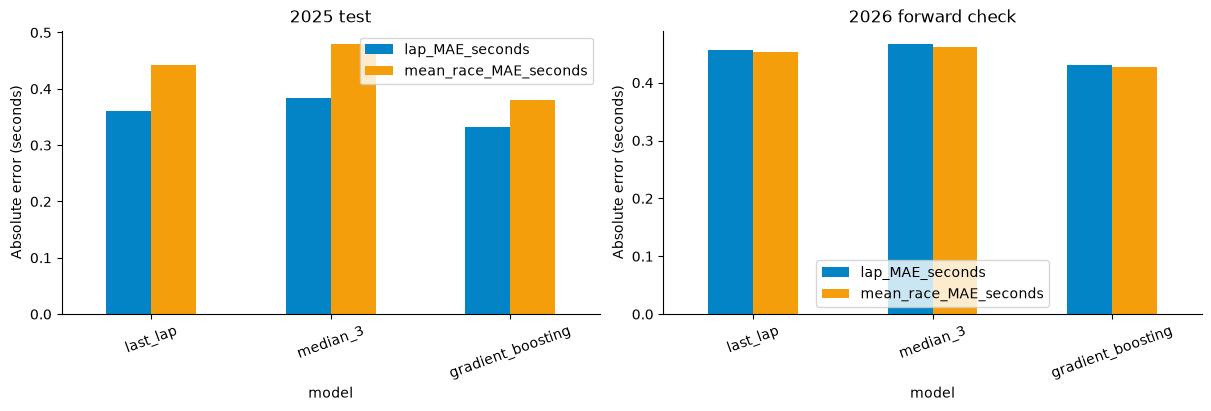

**Interpretation:** the validation-selected `gradient_boosting` changes mean race MAE by +13.8% on 2025 and +5.4% on 2026 relative to last lap (positive means lower error). No uncertainty interval is estimated here; these are point estimates.

In [11]:
test_scores = scores(pairs.split.eq('test'))
forward_scores = scores(pairs.split.eq('forward'))
display(Markdown('### 2025 test'))
display(test_scores.round(4))
display(Markdown('### 2026 forward check'))
display(forward_scores.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for ax, frame, title in [(axes[0], test_scores, '2025 test'), (axes[1], forward_scores, '2026 forward check')]:
    frame[['lap_MAE_seconds', 'mean_race_MAE_seconds']].plot.bar(ax=ax, color=['#0284c7', '#f59e0b'])
    ax.set(title=title, ylabel='Absolute error (seconds)'); ax.tick_params(axis='x', rotation=20)
plt.show()
test_gain = 100 * (1 - test_scores.loc[selected_model, 'mean_race_MAE_seconds'] / test_scores.loc['last_lap', 'mean_race_MAE_seconds'])
forward_gain = 100 * (1 - forward_scores.loc[selected_model, 'mean_race_MAE_seconds'] / forward_scores.loc['last_lap', 'mean_race_MAE_seconds'])
display(Markdown(f'**Interpretation:** the validation-selected `{selected_model}` changes mean race MAE '
                 f'by {test_gain:+.1f}% on 2025 and {forward_gain:+.1f}% on 2026 relative to last lap '
                 '(positive means lower error). No uncertainty interval is estimated here; these are point estimates.'))

## 11. Error analysis: where is the forecast less reliable?
Inspect the validation-selected model by race, compound, tyre age and weather. These are diagnostic tables, not permission to retune against the test set. Rain labels describe the latest observation at the current-lap cutoff, not the next lap's conditions.

In [12]:
diagnostics = pairs.loc[pairs.split.isin(['test', 'forward'])].copy()
diagnostics['absolute_error'] = (predictions.loc[diagnostics.index, selected_model] - diagnostics.next_timeSeconds).abs()
diagnostics['last_lap_error'] = (diagnostics.timeSeconds - diagnostics.next_timeSeconds).abs()
diagnostics['tyre_age_band'] = pd.cut(diagnostics.tyreLife, [0, 5, 15, 30, np.inf], labels=['1–5', '6–15', '16–30', '>30'])
diagnostics['weather_label'] = diagnostics.rainfall.map({0.0: 'no rain reported', 1.0: 'rain reported'}).fillna('weather missing')
for grouping in [['split', 'compound'], ['split', 'tyre_age_band'], ['split', 'weather_label']]:
    display(diagnostics.groupby(grouping, observed=True).agg(pairs=('number', 'size'), races=('race', 'nunique'),
                selected_MAE=('absolute_error', 'mean'), last_lap_MAE=('last_lap_error', 'mean')).round(3))
race_errors = diagnostics.groupby(['split', 'race']).agg(pairs=('number', 'size'), selected_MAE=('absolute_error', 'mean'), last_lap_MAE=('last_lap_error', 'mean'))
display(race_errors.sort_values('selected_MAE', ascending=False).head(10).round(3))
unknown = pd.DataFrame({name: X.loc[pairs.split.isin(['test', 'forward']), name].isna().groupby(pairs.split).mean() * 100 for name in categorical})
display(Markdown('### Unseen/missing categories (% of held-out rows)'))
display(unknown.round(2))

pairs  races  selected_MAE  last_lap_MAE
split   compound                                          
forward HARD       6062     14         0.423         0.448
        MEDIUM     4367     15         0.399         0.416
        SOFT       1883     14         0.529         0.571
test    HARD       8771     24         0.338         0.368
        MEDIUM     8193     24         0.317         0.346
        SOFT       2346     15         0.359         0.389

pairs  races  selected_MAE  last_lap_MAE
split   tyre_age_band                                          
forward 1–5             2032     15         0.538         0.545
        6–15            5351     15         0.427         0.445
        16–30           3891     15         0.362         0.406
        >30             1038     12         0.494         0.524
test    1–5             2834     24         0.405         0.454
        6–15            8059     24         0.310         0.334
        16–30           6887     22         0.309         0.337
        >30             1530     20         0.411         0.443

pairs  races  selected_MAE  last_lap_MAE
split   weather_label                                             
forward no rain reported  12191     15         0.431         0.456
        rain reported       121      1         0.402         0.459
test    no rain reported  19299     24         0.331         0.361
        rain reported        11      1         0.570         0.492

pairs  selected_MAE  last_lap_MAE
split   race                                             
test    2025/australia     15         1.244         1.979
        2025/britain      114         0.786         0.911
        2025/monaco      1067         0.640         0.653
forward 2026/monaco      1061         0.530         0.578
        2026/canada       743         0.511         0.613
        2026/hungary     1098         0.509         0.476
        2026/madrid       862         0.508         0.530
        2026/belgium      583         0.473         0.426
test    2025/singapore   1013         0.468         0.522
forward 2026/australia    742         0.463         0.494

### Unseen/missing categories (% of held-out rows)

,circuit,compound,driver,team
split,,,,
forward,33.97,0.0,37.56,26.10
test,19.85,0.0,35.13,19.76


## 12. Inspect one held-out race replay
This plot compares predicted and actual next-lap times at the **current-lap cutoff**. Gaps represent excluded target opportunities, not reconstructed data. Forecasts are generated offline from historical snapshots; this is not a live timing integration.

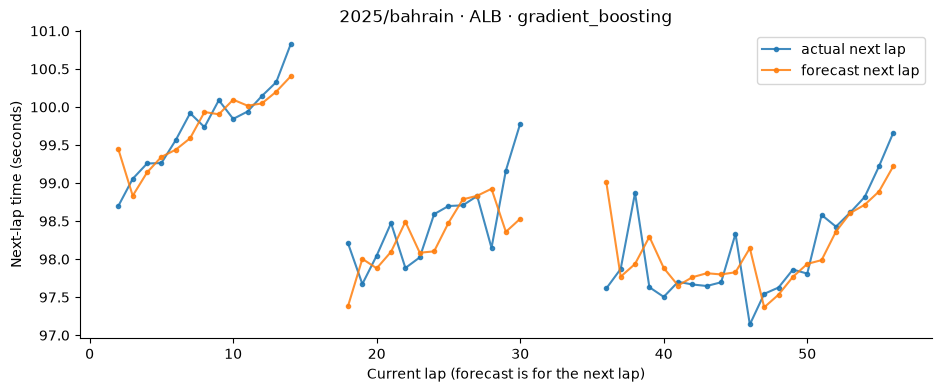

In [13]:
example_race = '2025/bahrain' if diagnostics.race.eq('2025/bahrain').any() else diagnostics.loc[diagnostics.split.eq('test'), 'race'].iloc[0]
example_driver = diagnostics.loc[diagnostics.race.eq(example_race), 'driver'].value_counts().index[0]
example = diagnostics.loc[diagnostics.race.eq(example_race) & diagnostics.driver.eq(example_driver)].sort_values('number')
plot = example.set_index('number')[['next_timeSeconds']].rename(columns={'next_timeSeconds': 'actual next lap'})
plot['forecast next lap'] = predictions.loc[example.index, selected_model].to_numpy()
plot = plot.reindex(range(int(example.number.min()), int(example.number.max()) + 1))
plot.plot(marker='.', alpha=.85)
plt.title(f'{example_race} · {example_driver} · {selected_model}')
plt.xlabel('Current lap (forecast is for the next lap)'); plt.ylabel('Next-lap time (seconds)'); plt.show()

## Findings from the first executed run (2026-10-01)

| Evaluation | Last-lap MAE | ML MAE | Last-lap mean race MAE | ML mean race MAE |
| --- | --- | --- | --- | --- |
| 2024 validation | 0.431 s | 0.398 s | 0.452 s | 0.420 s |
| 2025 test | 0.361 s | 0.332 s | 0.442 s | 0.381 s |
| 2026 forward check | 0.456 s | 0.431 s | 0.452 s | 0.428 s |

These are recorded-run results; rerunning on refreshed snapshots may change them. The executable score tables above are authoritative.

- Gradient boosting was selected on **2024**, then improved mean race MAE by **13.8% on 2025** and **5.4% on 2026** against last lap. No race-level significance interval has been estimated.
- The trailing three-lap median was worse than last lap in each evaluation partition: smoothing recent pace is not automatically helpful for predicting the next lap.
- In 2026 the ML bias is **−0.143 seconds** (prediction minus actual): on average it predicts too-fast laps. This suggests a calibration/generalization question for a later development experiment, not an instruction to correct the model using this test set.
- The 2025 cohort has only **11 rain-reported pairs from one race**. The 2026 cohort has **121 from one race**. These scores cannot establish wet-race performance.
- Known starting grid and finishing position have Spearman correlations of **0.507 (2000s), 0.627 (2010s), 0.631 (2020s)** in the filtered result cohort. This is association, not causality.
- The weather table includes **0°C track temperature**. A complete numeric column can still contain suspicious readings; investigate source context before deciding whether to flag or exclude them.
- **33.97% of 2026 circuit values**, **37.56% of driver values** and **26.10% of team values** are unseen/missing against training vocabularies. Names/aliases and roster changes are real generalization issues, not values to learn from the test set.

**Product implication:** the evidence supports an experimental race-replay pace forecast. It does not establish optimal pit timing, pure tyre degradation, prediction intervals or live accuracy.


## 13. What have we learned, and what comes next?

- **Coverage sets the scope.** Historical results can support outcome studies; detailed timing supports pace models. They should not be treated as interchangeable.
- **Context matters.** Raw lap time depends on circuit. Compound averages and tyre-age slopes mix race conditions and selection effects.
- **Recent pace is a strong baseline.** The validation/test tables tell us whether this first ML model adds enough value.
- **Good scores have a defined scope.** This target excludes pit transitions and interruptions. It is not a general race simulator or a forecast of every next lap.
- **A predictive relationship is not a causal effect.** Tyre age, weather and starting grid associations do not establish optimal strategy.

### Next experiments
1. Use chronological rolling folds within training years to check stability and tune a small model. For a later revised model, explicitly treat inspected 2025–2026 races as development data and reserve newly arriving races for fresh evaluation.
2. Test feature ablations on development races: recent pace only, then tyre context, then weather and categories. This checks which inputs add value.
3. Estimate and validate prediction intervals; inspect race-level uncertainty and rare conditions.
4. Backfill missing timing, reconcile circuit aliases, and separately define wet/interrupted-race targets.
5. Only then build a strategy sandbox with explicit pit-loss, traffic and tyre assumptions. A recorded pit-stop label is not an optimal-action label.

No confidence intervals, causal degradation estimates, model artifact, live serving or strategy recommendations are produced by this notebook.

In [14]:
output = ROOT / 'analysis' / 'ml'
output.mkdir(parents=True, exist_ok=True)
metrics = {'selected_on': '2024 validation mean race MAE', 'selected_model': selected_model,
           'training_seasons': sorted(pairs.loc[train_mask, 'season'].unique().tolist()),
           'target': 'adjacent eligible same-stint/compound next lap; 2019 onward; SOFT/MEDIUM/HARD; current tyre age known',
           'candidate_pairs': len(pairs), 'features': numeric + categorical,
           'model_params': model.get_params(), 'versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
           'validation_2024': validation_scores.reset_index().to_dict('records'),
           'test_2025': test_scores.reset_index().to_dict('records'),
           'forward_2026': forward_scores.reset_index().to_dict('records')}
(output / 'metrics.json').write_text(json.dumps(metrics, indent=2, allow_nan=False) + '\n')
print('Saved:', output / 'metrics.json')

Saved: /home/ashish/Documents/projects/pitwall-lab/analysis/ml/metrics.json


## Implementation references

- [pandas backward as-of joins](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html): weather observations at or before the cutoff.
- [Scikit-learn histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html): missing values, categorical inputs and explicit early-stopping controls.

These document the methods; all measured findings in this notebook come from the local snapshots.